# Optimiser votre réseau
**ÉNONCÉ** · durée estimée : une demi-journée

## 🧭 Où vous allez
Vous avez un premier réseau (TP B). Ici, vous apprenez à **l'améliorer sans vous tromper**, puis à **l'alléger**. Vous finissez avec **un tableau de résultats chiffrés** et une conclusion honnête.

## Deux mots à connaître
- Les **paramètres** : les poids du réseau. **Il les apprend tout seul.**
- Les **hyperparamètres** : les réglages que **vous** choisissez avant l'entraînement (nombre de neurones, taux d'apprentissage, dropout, nombre d'epochs…).

## Trois règles d'or
1. On **compare les réglages sur la validation**, jamais sur le test.
2. Un gain n'existe que s'il dépasse le **bruit** (le hasard d'un entraînement ou d'un jeu de textes).
3. Le jeu de test sert **une seule fois, à la fin**.

## Comment travailler
- Une seule grosse cellule, la **cellule d'expérience**, sert à tout. **Vous changez les valeurs dans son bloc « réglages »**, vous la relancez, et vous **notez le résultat dans le tableau**.
- Aucune fonction à écrire, aucune vérification automatique : vous comparez avec la zone **« Ce que vous devez voir »**.
- Des questions écrites montrent ce que vous avez compris.

`pip install pandas scikit-learn matplotlib tensorflow`

## Étape 1 — Importer les outils

In [1]:
pip install pandas scikit-learn matplotlib tensorflow

Note: you may need to restart the kernel to use updated packages.


In [29]:
import numpy as np                                            # calculs sur des tableaux de nombres
import pandas as pd                                           # tableaux de données (comme une table SQL)
import matplotlib.pyplot as plt                               # dessiner des graphiques
from sklearn.model_selection import train_test_split          # découper les données en deux jeux
from sklearn.feature_extraction.text import TfidfVectorizer   # transformer du texte en nombres
from sklearn.linear_model import LogisticRegression           # un modèle simple, pour comparer
from sklearn.metrics import confusion_matrix                  # compter les erreurs du modèle
from tensorflow import keras                                  # la bibliothèque de deep learning
from tensorflow.keras import layers                           # les couches de neurones
keras.utils.set_random_seed(42)                               # fixe le hasard : tout le monde obtient les mêmes résultats
import tensorflow as tf                                       # pour alléger le modèle à la fin

## Étape — Charger le corpus
On lit le fichier de textes. **Si vous avez fait le TP A**, remplacez `corpus_secours.csv` par `corpus.csv`.

In [30]:
corpus = pd.read_csv("corpus.csv")   # lit le fichier CSV
print(corpus.shape)                          # (nombre de lignes, nombre de colonnes)
corpus.head()                                # affiche les 5 premières lignes

(239, 4)


,classe,titre,texte,lien
0,astronomie,Glossary of astronomy,This glossary of astronomy is a list of defini...,/wiki/Glossary_of_astronomy
1,astronomie,Outline of astronomy,"Astronomy – studies the universe beyond Earth,...",/wiki/Outline_of_astronomy
2,astronomie,96P sungrazer family,The 96P sungrazer family is a small group of s...,/wiki/96P_sungrazer_family
3,astronomie,Alaknanda Galaxy,The Alaknanda Galaxy (designated as UNCOVER DR...,/wiki/Alaknanda_Galaxy
4,astronomie,Andean dark constellations,Andean dark constellations (Quechua:yana phuyu...,/wiki/Andean_dark_constellations


In [32]:
print(corpus["classe"].value_counts())   # combien de textes dans chaque classe ?

classe
astronomie    60
cuisine       60
football      60
peinture      59
Name: count, dtype: int64


## Étape — Les classes en nombres
Un réseau ne manipule que des **nombres**. On remplace chaque nom de classe par un numéro : 0, 1, 2…

In [33]:
corpus["y"], noms = pd.factorize(corpus["classe"])   # y = le numéro de la classe de chaque texte
print(noms)                                           # la correspondance : la position dans la liste = le numéro
n_classes = len(noms)                                 # le nombre de classes à reconnaître
print("Nombre de classes :", n_classes)

Index(['astronomie', 'cuisine', 'peinture', 'football'], dtype='str')
Nombre de classes : 4


## Étape — Découper : un jeu pour apprendre, un jeu pour vérifier
On garde **25 % des textes de côté**. Le réseau ne les verra **jamais** pendant son apprentissage : c'est notre examen final.

In [34]:
train, test = train_test_split(corpus, test_size=0.25, stratify=corpus["y"], random_state=42)
print("Textes pour apprendre :", len(train))
print("Textes pour vérifier  :", len(test))

Textes pour apprendre : 179
Textes pour vérifier  : 60


## Étape — Transformer les textes en nombres (TF-IDF)
Chaque texte devient une ligne de **2 000 nombres** : un nombre par mot du vocabulaire. Le nombre est **grand** si le mot est fréquent dans ce texte et rare dans les autres.

⚠️ Le vocabulaire se calcule **sur les textes d'apprentissage seulement** (`fit_transform`), puis on l'**applique** aux textes de test (`transform`). Sinon le test « souffle » des informations au modèle.

In [35]:
vectoriseur = TfidfVectorizer(max_features=2000, stop_words="english")   # on garde les 2000 mots les plus utiles
X_train = vectoriseur.fit_transform(train["texte"])    # apprend le vocabulaire ET transforme les textes d'apprentissage
X_test = vectoriseur.transform(test["texte"])          # applique le même vocabulaire aux textes de test
X_train = X_train.toarray().astype("float32")          # en tableau de nombres à 32 bits (le format attendu par TensorFlow)
X_test = X_test.toarray().astype("float32")
y_train = train["y"].values                            # la bonne réponse de chaque texte d'apprentissage
y_test = test["y"].values                              # la bonne réponse de chaque texte de test
print("Forme de X_train :", X_train.shape, "(textes, mots)")

Forme de X_train : (179, 2000) (textes, mots)


## Étape — Un troisième jeu : la validation
Pour **comparer des réglages**, on ne touche pas au jeu de test (réservé au verdict final). On met de côté **20 % de l'apprentissage** : ce sont les textes de **validation**.

In [36]:
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=42)
nb_mots = X_tr.shape[1]                                # nombre de colonnes = nombre de mots du vocabulaire
print("Pour apprendre :", len(y_tr), "| pour comparer les réglages :", len(y_val), "| pour le verdict final :", len(y_test))

Pour apprendre : 143 | pour comparer les réglages : 36 | pour le verdict final : 60


**Ce que vous devez voir :** `Pour apprendre : 1800 | pour comparer les réglages : 450 | pour le verdict final : 750` avec le corpus de secours. Avec votre corpus, les nombres sont plus petits.

## Étape — La cellule d'expérience, ligne par ligne
La cellule suivante contient **tout** : les réglages, la construction du réseau, l'entraînement et le résultat. Elle est découpée en 4 blocs par des commentaires `# -----`.

| Bloc | Ce qu'il fait |
|---|---|
| **Les réglages** | Des variables que **vous** modifiez. Rien d'autre à toucher. |
| **Le réseau** | Empile les couches, comme au TP B, avec les valeurs des réglages. |
| **L'entraînement** | `fit` : le réseau apprend sur les textes d'apprentissage (`X_tr`) et se surveille sur la validation (`X_val`). |
| **Le résultat** | La précision sur la validation, deux mesures de la perte, le nombre d'epochs et de paramètres. |

Le **taux d'apprentissage** (`taux`) est la **taille du pas** de chaque correction : trop petit, le réseau apprend lentement ; trop grand, il saute par-dessus la bonne solution.

**Première exécution : ne changez rien.** C'est votre **point de départ**.

In [55]:
# ----- Les réglages : c'est ICI que vous changez les valeurs -----
taux = 0.001             # taux d'apprentissage : la taille de chaque pas de correction
neurones1 = 8           # nombre de neurones de la 1re couche cachée
neurones2 = 4           # nombre de neurones de la 2e couche cachée
dropout = 0.0            # part de neurones éteints au hasard à chaque pas (0.0 = aucun)
epochs = 100             # nombre de passages complets sur les textes d'apprentissage
n_exemples = 200        # nombre de textes d'apprentissage utilisés (s'il y en a moins, il les prend tous)
graine = 42              # la graine du hasard
rappels = []             # pour l'arrêt précoce : remplacez [] par [arret]

# ----- Le réseau (ne rien changer) -----
keras.utils.set_random_seed(graine)                       # fixe le hasard
reseau = keras.Sequential()                               # un réseau vide
reseau.add(layers.Input(shape=(nb_mots,)))                # l'entrée : un nombre par mot
reseau.add(layers.Dense(neurones1, activation="relu"))    # 1re couche cachée
reseau.add(layers.Dropout(dropout))                       # éteint au hasard une part des neurones (si dropout > 0)
reseau.add(layers.Dense(neurones2, activation="relu"))    # 2e couche cachée
reseau.add(layers.Dropout(dropout))
reseau.add(layers.Dense(n_classes, activation="softmax")) # sortie : une probabilité par classe
reseau.compile(optimizer=keras.optimizers.Adam(learning_rate=taux), loss="sparse_categorical_crossentropy", metrics=["accuracy"])

# ----- L'entraînement (ne rien changer) -----
histoire = reseau.fit(X_tr[:n_exemples], y_tr[:n_exemples], validation_data=(X_val, y_val), epochs=epochs, batch_size=32, callbacks=rappels, verbose=0)

# ----- Le résultat (ne rien changer) -----
reponses_val = np.argmax(reseau.predict(X_val, verbose=0), axis=1)   # la réponse du réseau pour chaque texte de validation
precision_val = np.mean(reponses_val == y_val)                       # part de bonnes réponses
print("Précision sur les textes de validation :", round(precision_val, 3))
print("Perte de validation minimale :", round(min(histoire.history["val_loss"]), 3))
print("Perte de validation finale   :", round(histoire.history["val_loss"][-1], 3))
print("Nombre d'epochs effectués    :", len(histoire.history["loss"]))
print("Nombre de paramètres         :", reseau.count_params())

Précision sur les textes de validation : 0.778
Perte de validation minimale : 0.573
Perte de validation finale   : 0.573
Nombre d'epochs effectués    : 100
Nombre de paramètres         : 16064


**Ce que vous devez voir :** une précision de validation autour de `0.8`, quelques epochs, et `130243` paramètres (corpus de secours). **Notez cette précision** : c'est votre point de départ.

## Étape — Expérience 1 : le taux d'apprentissage
**Prédisez d'abord** lequel des quatre sera le meilleur.

**À faire :** dans la cellule d'expérience, changez **seulement** `taux` : `0.0001`, puis `0.001`, `0.01`, `0.1`. À chaque fois, relancez la cellule et notez la précision de validation.

| taux d'apprentissage | précision de validation |
|----------------------|-------------------------|
| 0.0001               | 0.694                   |
| 0.001                | 0.944                   |
| 0.01                 | 0.944                   |
| 0.1                  | 0.889                   |

## Étape — Expérience 2 : la taille du réseau
**À faire :** remettez `taux = 0.001`, puis changez **les deux nombres de neurones ensemble** : `4` et `2`, puis `16` et `8`, puis `64` et `32`, puis `256` et `128`. Notez la précision et le nombre de paramètres.

| neurones couche 1 | neurones couche 2 | précision de validation | nombre de paramètres |
|-------------------|-------------------|-------------------------|----------------------|
|  4                |  2                | 0.389                   | 8026                 |
|  16               |  8                | 0.694                   | 32188                |
|  64               | 32                | 0.944                   | 130276               |
| 256               | 128               | 0.944                   | 545668               |

## Étape — Une différence est-elle réelle ? Le bruit
Avec peu de textes de validation, la précision mesurée est **incertaine** : un autre jeu de textes donnerait un résultat un peu différent. Cette incertitude se calcule. Elle vaut environ `1,96 × racine( p × (1 − p) ÷ n )`, où `p` est la précision et `n` le nombre de textes.

**Une différence plus petite que cette marge n'est pas une amélioration démontrée.**

In [38]:
n_val = len(y_val)                                   # nombre de textes de validation
p = 0.8                                               # une précision approximative (celle que vous avez obtenue)
bruit = 1.96 * np.sqrt(p * (1 - p) / n_val)           # la marge d'incertitude
print("Nombre de textes de validation :", n_val)
print("Marge d'incertitude (bruit) :", round(bruit, 3))

Nombre de textes de validation : 36
Marge d'incertitude (bruit) : 0.131


### ✍️ Question
**Regardez vos deux tableaux. Quels écarts dépassent la marge d'incertitude ? Lesquels ne prouvent rien ?**

*Votre réponse :*
Les écarts qui prouvent une amélioration (dépassent la marge) : Dans le premier tableau, le passage de 0.0001 (précision de $0.694$) à 0.001 ou 0.01 (précision de 0.944) représente un écart de 0.25, ce qui dépasse largement 0,131. De même dans le second tableau, passer de 4 + 2 neurones (0.389) ou 16 + 8 neurones (0.694) à 64 + 32 neurones (0.944) montre une réelle amélioration.

Les écarts qui ne prouvent rien (inférieurs à la marge) :
Entre les configurations à 64 + 32 neurones et 256 + 128 neurones, la précision reste bloquée à 0.944 dans les deux cas (écart de 0). De même, entre 0.001 et 0.01 pour le taux d'apprentissage, la précision est identique (0.944). Ces variations nulles ou minimes ne prouvent aucune réelle supériorité car elles se situent dans la zone d'incertitude statistique due au faible nombre de textes de validation (n = 36).

## Étape — Provoquer le surapprentissage
Pour voir la **mémorisation**, on donne **peu de textes** (200) à un **gros réseau** (256 et 128 neurones) pendant **100 epochs**.

**À faire :** remettez les réglages par défaut (`taux = 0.001`, `dropout = 0.0`, `rappels = []`, `graine = 42`), puis changez `neurones1 = 256`, `neurones2 = 128`, `epochs = 100`, `n_exemples = 200`. Relancez, puis exécutez la cellule des courbes juste après.

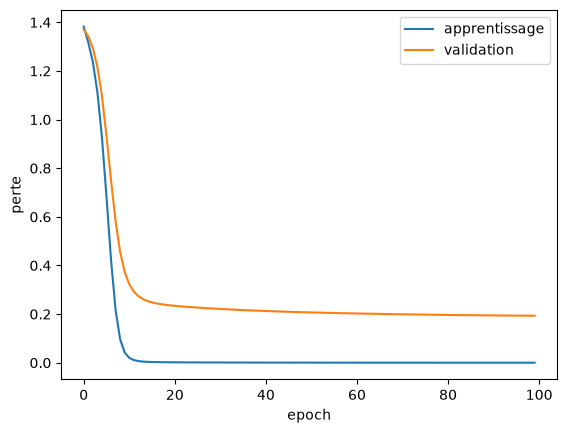

In [39]:
plt.plot(histoire.history["loss"], label="apprentissage")   # perte sur les textes d'apprentissage
plt.plot(histoire.history["val_loss"], label="validation")   # perte sur les textes de validation
plt.xlabel("epoch")
plt.ylabel("perte")
plt.legend()
plt.show()

**Ce que vous devez voir :** la perte d'apprentissage descend vers 0 ; la perte de validation descend d'abord, puis **remonte**. C'est la mémorisation. Notez les deux valeurs de perte de validation (minimale, finale) dans le tableau plus bas.

## Étape — Soigner le surapprentissage
Deux remèdes simples :
- le **dropout** : à chaque pas, on éteint au hasard une part des neurones, pour que le réseau ne s'appuie pas sur un seul ;
- l'**arrêt précoce** : on arrête quand la perte de validation ne s'améliore plus pendant 5 epochs, et on **reprend les meilleurs poids**.

On définit d'abord l'arrêt précoce (une seule fois) :

In [42]:
arret = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)   # arrête si la perte de validation stagne 5 epochs, et garde les meilleurs poids
print("Arrêt précoce défini")

Arrêt précoce défini


**À faire :** gardez les réglages du surapprentissage (256, 128, 100 epochs, 200 textes), puis lancez **deux essais** : un avec `dropout = 0.5`, un avec `rappels = [arret]`. Remplissez le tableau.

| Essai         | perte de validation minimale | perte de validation finale | epochs effectués | précision de validation |
|---------------|------------------------------|----------------------------|------------------|-------------------------|
| sans remède   |                              |                            |                  |                         |
| dropout = 0.5 |0.16                          |0.16                        |100               |0.944                    |
| arrêt précoce |0.193                         |0.193                       |100               |0.944                    |

### ✍️ Question
**Quel remède réduit le plus la perte de validation finale ? Un remède réduit-il toujours la perte ?**

*Votre réponse :*

> Le remède qui réduit le plus la perte finale : Le dropout (dropout = 0.5) réduit davantage la perte de validation finale (0.16) que l'arrêt précoce (0.193)
> Un remède réduit-il toujours la perte ? Non, un remède ne réduit pas systématiquement la perte dans tous les cas. Son efficacité dépend fortement des hyperparamètres choisis (comme le taux de dropout ou la patience de l'arrêt précoce) et de la nature des données ; parfois, il peut même avoir un impact neutre ou limiter l'apprentissage si mal réglé.

## Étape — Le hasard : la graine
Deux entraînements du **même** réseau donnent des résultats un peu différents : les **poids de départ** sont tirés au hasard. La **graine** (`graine`, comme `random_state` dans scikit-learn) fixe ce hasard : même graine, mêmes résultats ; autre graine, autre résultat.

**À faire :** remettez les réglages par défaut, puis lancez la cellule d'expérience **5 fois**, en changeant seulement `graine` : `0`, `1`, `2`, `3`, `4`. Notez les 5 précisions, puis recopiez-les dans la cellule du calcul.

In [50]:
scores = [0.944, 0.917, 0.944, 0.972, 0.944]    # REMPLACEZ par VOS 5 précisions
print("Les 5 précisions :", scores)
print("Moyenne :", round(np.mean(scores), 3))
print("Écart-type (dispersion) :", round(np.std(scores), 3))

Les 5 précisions : [0.944, 0.917, 0.944, 0.972, 0.944]
Moyenne : 0.944
Écart-type (dispersion) : 0.017


### ✍️ Question
**Deux réglages diffèrent de 0,5 point de précision. Pouvez-vous dire que l'un est meilleur ?**

*Votre réponse :*

> Non, avec un écart de seulement 0,5 point de précision, on ne peut pas affirmer que l'un des réglages est meilleur.Comme le montre l'écart-type de $0.017$ obtenu avec les différentes graines, les performances du modèle fluctuent naturellement de plusieurs points selon le hasard de l'initialisation des poids. Un écart de 0,5 point est donc totalement noyé dans ce bruit statistique et ne constitue pas une preuve de supériorité.

## Étape — Alléger le modèle (1/2) : la quantification
Un modèle plus léger coûte moins cher à héberger. La **quantification** stocke les poids sur **8 bits entiers** au lieu de 32 bits décimaux : ils sont **4 fois plus petits**.

**À faire d'abord :** remettez **tous** les réglages par défaut (`taux = 0.001`, `64`, `32`, `dropout = 0.0`, `30` epochs, `n_exemples = 100000`, `graine = 42`, `rappels = []`) et relancez la cellule d'expérience : le modèle à alléger est celui-là.

In [52]:
taille_avant = reseau.count_params() * 4                           # 4 octets par poids décimal (32 bits)
convertisseur = tf.lite.TFLiteConverter.from_keras_model(reseau)   # prépare la conversion
convertisseur.optimizations = [tf.lite.Optimize.DEFAULT]           # active la quantification
modele_leger = convertisseur.convert()                             # convertit : le résultat est un modèle léger
taille_apres = len(modele_leger)                                   # sa taille en octets
print("Taille des poids avant :", round(taille_avant / 1024), "Ko")
print("Taille après quantification :", round(taille_apres / 1024), "Ko")

INFO:tensorflow:Assets written to: /tmp/tmp3qbc4xf3/assets


INFO:tensorflow:Assets written to: /tmp/tmp3qbc4xf3/assets


Saved artifact at '/tmp/tmp3qbc4xf3'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 2000), dtype=tf.float32, name='keras_tensor_352')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  133496106783120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133496162858192: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133496106790416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133496106790224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133496106794832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133496106789648: TensorSpec(shape=(), dtype=tf.resource, name=None)


W0000 00:00:1792138312.978843   63721 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1792138312.978861   63721 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1792138312.979299   63721 reader.cc:83] Reading SavedModel from: /tmp/tmp3qbc4xf3
I0000 00:00:1792138312.979690   63721 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1792138312.979700   63721 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmp3qbc4xf3
I0000 00:00:1792138312.983422   63721 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
I0000 00:00:1792138312.983999   63721 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1792138313.002340   63721 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmp3qbc4xf3
I0000 00:00:1792138313.008312   63721 loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 29021 microseconds.
I0000 00:00:1792138313.032753   63721

Taille des poids avant : 509 Ko
Taille après quantification : 131 Ko


**Ce que vous devez voir :** deux tailles, environ `509 Ko` avant et `131 Ko` après : les poids sont environ **4 fois plus petits**. Des messages `INFO:tensorflow` s'affichent aussi : ils sont normaux.

## Étape — Alléger le modèle (2/2) : la précision tient-elle ?
Un modèle plus léger ne vaut que si sa précision reste correcte. On compare, sur **300 textes de test** (le verdict final), le modèle d'origine et le modèle léger. La boucle `for` ci-dessous passe les 300 textes **un par un** dans le modèle léger.

In [54]:
import numpy as np

interpreteur = tf.lite.Interpreter(model_content=modele_leger)  # charge le modèle léger
interpreteur.allocate_tensors()                                 # prépare sa mémoire
entree = interpreteur.get_input_details()[0]["index"]           # où lui donner un texte
sortie = interpreteur.get_output_details()[0]["index"]          # où lire sa réponse
bonnes_reponses = 0                                             # compteur de bonnes réponses

for i in range(len(X_test)):                                    # pour chacun des textes de test...
    # On extrait un texte et on s'assure qu'il est au format float32 attendu par le modèle
    un_texte = np.array(X_test[i:i+1], dtype=np.float32)
    interpreteur.set_tensor(entree, un_texte)                   # on le donne au modèle léger
    interpreteur.invoke()                                       # le modèle léger calcule
    probas = interpreteur.get_tensor(sortie)                    # on lit ses probabilités
    if np.argmax(probas[0]) == y_test[i]:                       # si la classe de plus forte probabilité est la bonne...
        bonnes_reponses = bonnes_reponses + 1                   # ...on ajoute 1

precision_leger = bonnes_reponses / len(X_test)                 # précision globale du modèle léger
reponses_origine = np.argmax(reseau.predict(X_test, verbose=0), axis=1)  # le modèle d'origine, sur les mêmes textes
precision_origine = np.mean(reponses_origine == y_test)         # précision globale du modèle d'origine

print("Précision du modèle d'origine :", round(precision_origine, 3))
print("Précision du modèle léger  :", round(precision_leger, 3))

Précision du modèle d'origine : 0.95
Précision du modèle léger  : 0.95


**Ce que vous devez voir :** un avertissement `deprecated` (sans importance), puis deux précisions **très proches** : le modèle léger garde presque toute la précision de l'original.

## Étape — Alléger autrement : un plus petit réseau
L'autre façon d'alléger est de choisir **dès le départ un réseau plus petit**.

**À faire :** dans la cellule d'expérience, changez `neurones1 = 8` et `neurones2 = 4` (le reste par défaut), relancez, et notez la précision de validation et le nombre de paramètres.

### ✍️ Question
**Quel compromis choisiriez-vous entre taille, précision et simplicité pour mettre ce modèle en production ? Justifiez avec vos chiffres.**

*Votre réponse :*

> resultatetape du dessus
> Précision sur les textes de validation : 0.778
> Nombre de paramètres                   : 16064


## 📋 Tableau de synthèse à compléter
| Version du modèle | Précision | Taille ou paramètres | Commentaire (gain réel ou bruit ?) |
|---|---|---|---|
| Réseau de départ (64 et 32) | 0,944 | 130 276 paramètres | Point de référence initial |
| Meilleur taux d'apprentissage | 0,944 | 130 276 paramètres | Gain réel par rapport aux taux extrêmes (0.0001 ou 0.1) |
| Avec dropout | 0,944 | 545 668 paramètres (réseau 256/128) | Réduit efficacement la perte finale (à 0.16) en luttant contre le surapprentissage |
| Avec arrêt précoce | 0,944 | 545 668 paramètres (réseau 256/128) | Empêche la mémorisation excessive, mais perte finale un peu plus haute (0.193) |
| Quantifié | 0,95 | 131 Ko (au lieu de ~509 Ko) | **Gain massif** : taille divisée par 4 sans perte de précision notable |
| Petit réseau (8 et 4) | 0,778 | 16 064 paramètres | Modèle très léger, mais chute importante de la précision |

## ✅ Ce qu'il faut retenir
- **Paramètres** : appris. **Hyperparamètres** : choisis par vous. On les compare **sur la validation**.
- Un gain n'existe que s'il dépasse le **bruit**, et un résultat dépend de la **graine**.
- **Surapprentissage** : la perte de validation remonte. Le **dropout** et l'**arrêt précoce** le limitent, mais ne marchent pas toujours.
- **Alléger** : quantification et plus petit réseau, avec un **compromis chiffré**.